In [4]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

Image Shape: (28, 28)


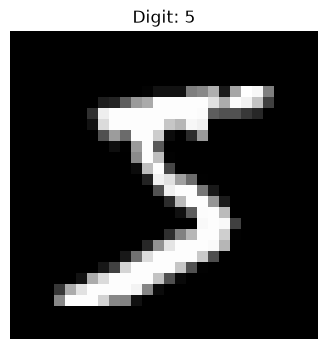

In [5]:
image = X_train[0]
label = y_train[0]

print("Image Shape:", image.shape)

plt.figure(figsize=(4,4))
plt.imshow(image, cmap="gray")
plt.title(f"Digit: {label}")
plt.axis("off")
plt.show()

In [6]:
#normalizing the pixel values

X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0
print("Minimum pixel:", X_train.min())
print("Maximum pixel:", X_train.max())

Minimum pixel: 0.0
Maximum pixel: 1.0


In [7]:
#convolution

def convolution(image, kernel, stride=1):

    img_height, img_width = image.shape
    kernel_height, kernel_width = kernel.shape

    output_height = (img_height - kernel_height) // stride + 1
    output_width = (img_width - kernel_width) // stride + 1

    output = np.zeros((output_height, output_width))

    for i in range(output_height):
        for j in range(output_width):
            for k in range(kernel_height):
                for l in range(kernel_width):
                    m = i * stride + k
                    n = j * stride + l
                    output[i, j] += image[m, n] * kernel[k, l]

    return output

In [8]:
kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

feature_map = convolution(image, kernel)

print("Feature Map Shape:", feature_map.shape)

Feature Map Shape: (26, 26)


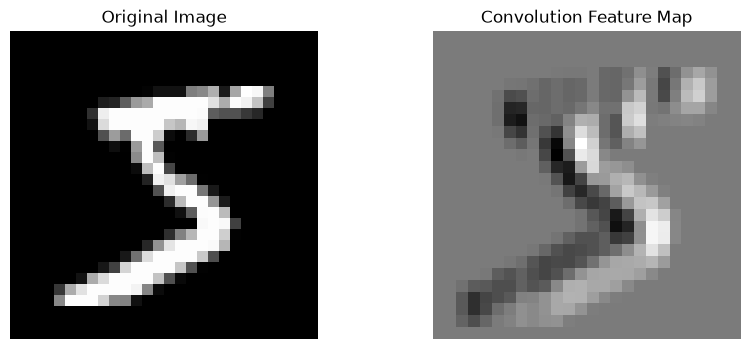

In [9]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(feature_map, cmap="gray")
plt.title("Convolution Feature Map")
plt.axis("off")

plt.show()


In [10]:
#relu

def relu(x):
    return np.maximum(0, x)

In [11]:
activated = relu(feature_map)

print("Before ReLU:")
print(feature_map[:5, :5])

print("After ReLU:")
print(activated[:5, :5])

Before ReLU:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
After ReLU:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]


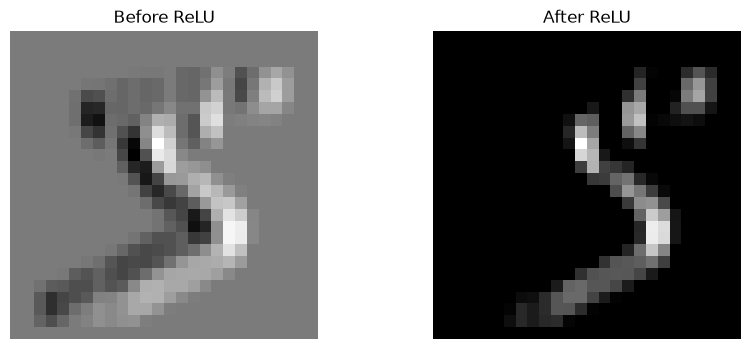

In [12]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(feature_map, cmap="gray")
plt.title("Before ReLU")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(activated, cmap="gray")
plt.title("After ReLU")
plt.axis("off")

plt.show()

In [13]:
#max pooling

def max_pool(image, poolsize=2, stride=2):
    height, width = image.shape
    output_height = (height - poolsize) // stride + 1
    output_width = (width - poolsize) // stride + 1

    output = np.zeros((output_height, output_width))

    for i in range(0, output_height, stride):
        for j in range(0, output_width, stride):
            max_value = 0
            for m in range(poolsize):
                for n in range(poolsize):
                    max_value = np.max(image[i + m, j + n], 0)
            output[i, j] = max_value

    return output

In [14]:
pooled = max_pool(activated)


print("Before Pooling:", activated.shape)
print("After Pooling:", pooled.shape)

Before Pooling: (26, 26)
After Pooling: (13, 13)


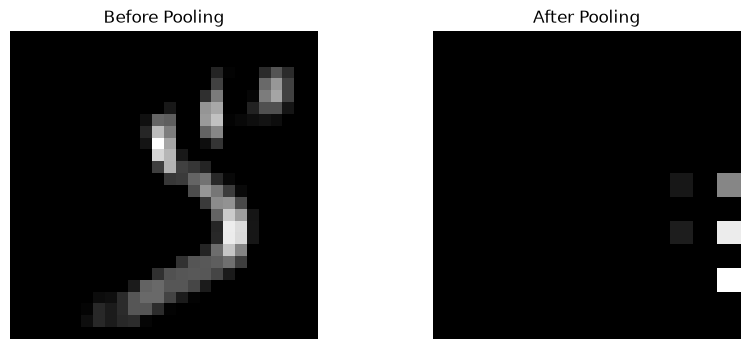

In [15]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(activated, cmap="gray")
plt.title("Before Pooling")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(pooled, cmap="gray")
plt.title("After Pooling")
plt.axis("off")

plt.show()

In [16]:
#multiple kernels

kernel1 = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

kernel2 = np.array([
    [1, 1, 1],
    [0, 0, 0],
    [-1, -1, -1]
])

kernel3 = np.array([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0]
])

kernels = [kernel1, kernel2, kernel3]

In [17]:
feature_maps = []

for kernel in kernels:
    conv = convolution(image, kernel)
    activated = relu(conv)
    pooled = max_pool(activated)

    feature_maps.append(pooled)

for i, fmap in enumerate(feature_maps):
    print(f"Filter {i+1} Output Shape: {fmap.shape}")

Filter 1 Output Shape: (13, 13)
Filter 2 Output Shape: (13, 13)
Filter 3 Output Shape: (13, 13)


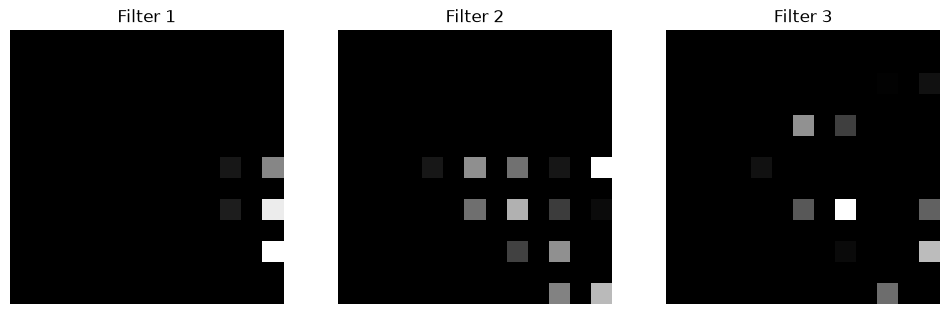

In [18]:
plt.figure(figsize=(12, 4))

for i, fmap in enumerate(feature_maps):
    plt.subplot(1, 3, i + 1)
    plt.imshow(fmap, cmap="gray")
    plt.title(f"Filter {i + 1}")
    plt.axis("off")

plt.show()

In [19]:
combined = np.stack(feature_maps)
print("Combined Shape:", combined.shape)

Combined Shape: (3, 13, 13)


In [20]:
#multiple channel convolution

def multi_channel_convolution(input_data, filters):
    num_filters, input_channels, kernel_height, kernel_width = filters.shape
    _, height, width = input_data.shape

    output_height = height - kernel_height + 1
    output_width = width - kernel_width + 1

    output = np.zeros((num_filters, output_height, output_width))

    for f in range(num_filters):
        for i in range(output_height):
            for j in range(output_width):
                total = 0
                for c in range(input_channels):
                    region = input_data[
                        c,
                        i:i+kernel_height,
                        j:j+kernel_width
                    ]

                    total += np.sum(region * filters[f, c])

                output[f, i, j] = total
    return output

In [21]:
input_data = combined

filters = np.random.randn(5, 3, 3, 3)

output = multi_channel_convolution(input_data, filters)

print("Input Shape:", input_data.shape)
print("Filter Shape:", filters.shape)
print("Output Shape:", output.shape)

Input Shape: (3, 13, 13)
Filter Shape: (5, 3, 3, 3)
Output Shape: (5, 11, 11)


In [22]:
#relu on all 5 feature maps

output_activated = relu(output)
print("Before ReLU:", output.shape)
print("After ReLU:", output_activated.shape)

Before ReLU: (5, 11, 11)
After ReLU: (5, 11, 11)


In [23]:
#max pooling on all 5 channels

def max_pool_channels(data, poolsize=2, stride=2):
    num_channels, height, width = data.shape

    output_height = (height - poolsize) // stride + 1
    output_width = (width - poolsize) // stride + 1

    pooled = np.zeros((num_channels, output_height, output_width))

    for c in range(num_channels):
        pooled[c] = max_pool(data[c], poolsize, stride)

    return pooled

In [24]:
output_pooled = max_pool_channels(output_activated)

print("Before pooling:", output_activated.shape)
print("After pooling:", output_pooled.shape)

Before pooling: (5, 11, 11)
After pooling: (5, 5, 5)


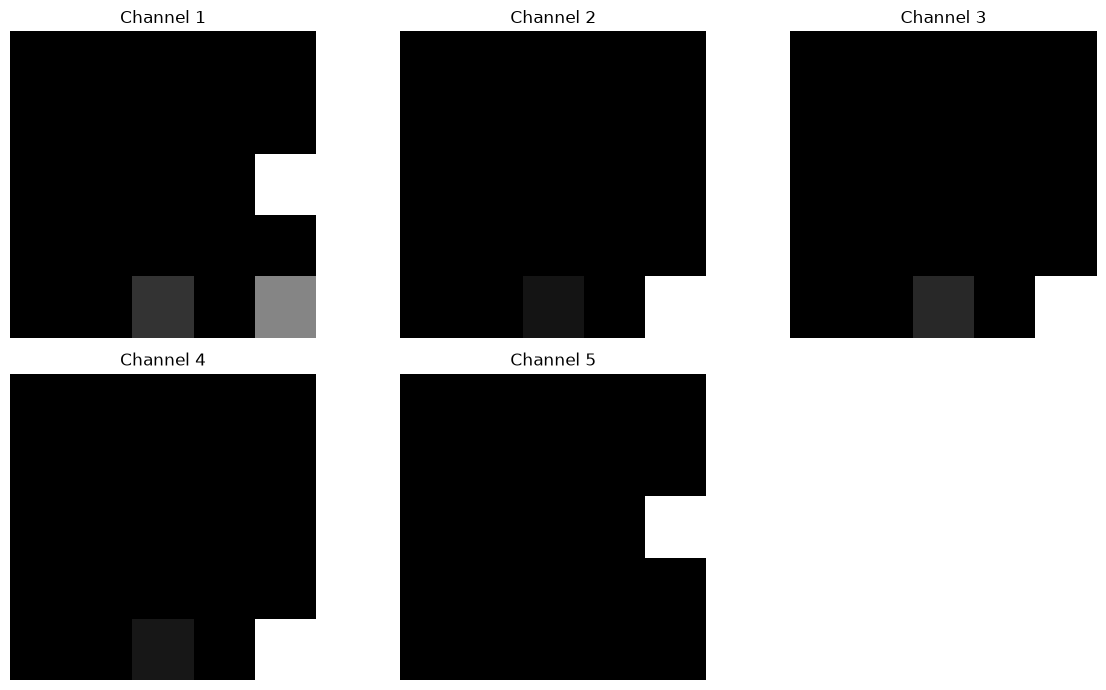

Output Pooled Size: 125


In [25]:
plt.figure(figsize=(12, 7))

for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.imshow(output_pooled[i], cmap="gray")
    plt.title(f"Channel {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Output Pooled Size:", output_pooled.size)

In [26]:
#flatten

flattened = output_pooled.flatten()

print("Before flattening:", output_pooled.shape)
print("After flattening:", flattened.shape)
print("Number of Values:", len(flattened))

Before flattening: (5, 5, 5)
After flattening: (125,)
Number of Values: 125


In [27]:
#making flatten a column vector

x = flattened.reshape(125, 1)
print(x.shape)

(125, 1)


In [28]:
#dense layer
W = np.random.randn(10, 125) * 0.01

b = np.zeros((10, 1))

#dense layer calculation
z = W @ x + b

print("Weight shape:", W.shape)
print("Input shape:", x.shape)
print("Bias shape:", b.shape)
print("Output shape:", z.shape)


print("Logits")
print(z)

Weight shape: (10, 125)
Input shape: (125, 1)
Bias shape: (10, 1)
Output shape: (10, 1)
Logits
[[  5.04571904]
 [  6.48423863]
 [  0.90894906]
 [ 10.72443153]
 [-11.40877321]
 [ -4.39269334]
 [ 14.18033572]
 [  2.94713195]
 [ -3.33703529]
 [  2.31350922]]


In [29]:
#softmax

def softmax(z):
    exp_z = np.exp(z - np.max(z))
    return exp_z / np.sum(exp_z)

probabilities = softmax(z)

print("Probabilities")
print(probabilities)

print("Sum:", np.sum(probabilities))

Probabilities
[[1.04507249e-04]
 [4.40440792e-04]
 [1.66943702e-06]
 [3.05759468e-02]
 [7.46536819e-12]
 [8.31947657e-09]
 [9.68857787e-01]
 [1.28156791e-05]
 [2.39090582e-08]
 [6.80084330e-06]]
Sum: 1.0000000000000002


In [30]:
predicted_digit = np.argmax(probabilities)

print("Predicited digit:", predicted_digit)
print("Actual digit:", y_train[0])

Predicited digit: 6
Actual digit: 5


In [39]:
#category cross entropy loss

def cross_entropy_loss(x):
    return -np.log(x)

print("Loss:", cross_entropy_loss(probabilities[y_train[0], 0]))

Loss: 18.604666495943327


In [40]:
actual_label = y_train[0]

y = np.zeros((10, 1))
y[actual_label] = 1

p = probabilities.reshape(10, 1)

#gradient
dz = p - y

#gradients of dense layer
dW = dz @ x.T
db = dz

print("Actual Label:", actual_label)
print("dz shape:", dz.shape)
print("dW shape:", dW.shape)
print("db shape:", db.shape)

Actual Label: 5
dz shape: (10, 1)
dW shape: (10, 125)
db shape: (10, 1)


In [53]:
#updating the weights

learning_rate = 0.01

W = W - learning_rate * dW
b = b - learning_rate * db

In [54]:
#new logits

z_new = W @ x + b

print("New logits:")
print(z_new)
print("Shape:", z_new.shape)

New logits:
[[-3.73649669e+01]
 [-1.72253564e+02]
 [ 2.31465250e-01]
 [-1.23974758e+04]
 [-1.14087762e+01]
 [ 4.05811336e+05]
 [-3.93163552e+05]
 [-2.25367223e+00]
 [-3.34673796e+00]
 [-4.46379984e-01]]
Shape: (10, 1)


In [55]:
probabilities_new = softmax(z_new)

print("New Probabilities:")
print(probabilities_new)

print("Sum:", np.sum(probabilities_new))

New Probabilities:
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]]
Sum: 1.0


In [57]:
new_loss = cross_entropy_loss(probabilities_new[actual_label, 0])

print("New Loss:", new_loss)

New Loss: -0.0


In [59]:
dx = W.T @ dz

print("Gradient Shape:", dx.shape)

Gradient Shape: (125, 1)


In [60]:
d_pooled = dx.reshape(output_pooled.shape)

print("Gradient shape:", d_pooled.shape)

Gradient shape: (5, 5, 5)
